# Day 4 · Explain and calibrate | اليوم الرابع

**Naif Faraj AlDosari · SDA-DSC-211**

Day 3 used weighted LightGBM scores to choose a review threshold under a capacity limit. Day 4 asks what drives those scores, whether the probabilities agree with observed outcomes, and whether a threshold chosen on development data still fits the review queue. This lab fits its own weighted LightGBM on a dedicated earlier split. [Day 4 guide](https://github.com/almiyead-rgb/sda-dsc-211-student-template/blob/main/DAY4_GUIDE.md)

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Day 4 · Explain the model and test its probabilities</h2>
<p><strong>SDA-DSC-211 · Tamweel Lite · 60-minute lab · Free CPU</strong></p>
<p>Ask two different questions: what information does the fitted model use, and do its probability scores agree with observed event frequency on a separate period? Compare permutation importance, global and local SHAP explanations, calibration, stability and the operational effect of a diagnostic review zone.</p>
<p><strong>Deliverable:</strong> <code>reports/INTERPRETABILITY_REPORT.md</code>, six figures and the complete evidence bundle.</p>
<p><strong>Boundary:</strong> the data are fictional. Explanations describe a fitted model, not causes, protected-trait effects or real financing decisions. Calibration improvement is measured, never assumed.</p>
<table><tr><th>Minutes</th><th>Your task</th></tr><tr><td>0–10</td><td>Separate data roles and inspect permutation importance</td></tr><tr><td>10–25</td><td>Read the beeswarm and SHAP output unit</td></tr><tr><td>25–35</td><td>Explain one synthetic request and test local stability</td></tr><tr><td>35–48</td><td>Compare calibration, Brier score and ECE</td></tr><tr><td>48–54</td><td>Read stability limits and review capacity</td></tr><tr><td>54–60</td><td>Complete the report and export evidence</td></tr></table>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>اليوم الرابع · فسّر النموذج واختبر احتمالاته</h2>
<p><strong>SDA-DSC-211 · Tamweel Lite · لاب 60 دقيقة · CPU مجاني</strong></p>
<p>اطرح سؤالين مختلفين: ما المعلومات التي يستخدمها النموذج المدرّب، وهل تتفق درجات احتماله مع تكرار الحدث المرصود في فترة منفصلة؟ قارن أهمية التبديل، وتفسيرات SHAP العامة والمحلية، والمعايرة، والاستقرار، والأثر التشغيلي لمنطقة مراجعة تشخيصية.</p>
<p><strong>التسليم:</strong> ملف <code>reports/INTERPRETABILITY_REPORT.md</code> وستة رسوم وحزمة الأدلة الكاملة.</p>
<p><strong>الحدود:</strong> البيانات اصطناعية. تصف التفسيرات نموذجًا مدرّبًا، ولا تثبت الأسباب أو أثر السمات المحمية أو قرارات تمويل حقيقية. يُقاس تحسن المعايرة ولا يُفترض مسبقًا.</p>
<table><tr><th>الدقائق</th><th>مهمتك</th></tr><tr><td>0–10</td><td>افصل أدوار البيانات وافحص أهمية التبديل</td></tr><tr><td>10–25</td><td>اقرأ beeswarm ووحدة مخرجات SHAP</td></tr><tr><td>25–35</td><td>فسّر طلبًا اصطناعيًا واختبر الاستقرار المحلي</td></tr><tr><td>35–48</td><td>قارن المعايرة وBrier وECE</td></tr><tr><td>48–54</td><td>اقرأ حدود الاستقرار وسعة المراجعة</td></tr><tr><td>54–60</td><td>أكمل التقرير وصدّر الأدلة</td></tr></table>
</td>
</tr>
</table>

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Official daily requirement</h2>
<p>Run all cells, compare the generated files with EXPECTED_RESULTS.md, then answer only the single question at the end of this notebook in your repository README. Legacy reflection variables inside code cells are compatibility fields; leave them unchanged.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>المطلوب اليومي المعتمد</h2>
<p>شغّل جميع الخلايا، وقارن الملفات الناتجة بصفحة EXPECTED_RESULTS.md، ثم أجب فقط عن السؤال الواحد في نهاية هذا الدفتر داخل README في مستودعك. حقول الانعكاس القديمة داخل خلايا الكود مخصصة للتوافق؛ اتركها دون تعديل.</p>
</td>
</tr>
</table>

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>1. Prepare a controlled environment</h2>
<p>Open a fresh free-CPU session and choose <strong>Runtime → Run all</strong>. Setup verifies pinned packages, file hashes and support assets before any model work.</p>
<ul><li>Keep <code>FAST_MODE=True</code> and <code>USE_SHAP_EXAMPLE=False</code> for the primary run.</li><li>Use at most two CPU threads; no GPU, Drive mount, API key or paid service is required.</li><li>The fitted estimator is frozen before calibration. <code>FrozenEstimator</code> allows sigmoid calibration without retraining on calibration rows.</li><li>Do not replace the time/customer role split with a random split.</li></ul>
<p>If setup requests a restart, restart the session and run from the beginning. Never bypass a checksum failure.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>1. جهّز بيئة تشغيل محكومة</h2>
<p>افتح جلسة CPU مجانية جديدة ثم نفّذ <strong>Runtime → Run all</strong>. يتحقق الإعداد من الحزم المثبتة وبصمات الملفات وأصول الدعم قبل أي عمل على النموذج.</p>
<ul><li>اترك <code>FAST_MODE=True</code> و<code>USE_SHAP_EXAMPLE=False</code> في التشغيل الأساسي.</li><li>استخدم خيطي CPU كحد أقصى؛ لا تحتاج إلى GPU أو ربط Drive أو مفتاح API أو خدمة مدفوعة.</li><li>يُجمّد النموذج قبل المعايرة. يتيح <code>FrozenEstimator</code> تعلم تحويل sigmoid دون إعادة التدريب على صفوف المعايرة.</li><li>لا تستبدل تقسيم الزمن والعملاء بتقسيم عشوائي.</li></ul>
<p>إذا طلب الإعداد إعادة التشغيل، أعد الجلسة ثم شغّل من البداية. لا تتجاوز فشل البصمة.</p>
</td>
</tr>
</table>

In [1]:
# Verify the released helpers before reusing the split and policy rules.
from pathlib import Path
import hashlib, importlib.util, os, runpy, sys, time, urllib.request, urllib.error

RUN_STARTED = time.perf_counter()
COURSE_REVISION = "fe0c0204e6076a7ac2139b7336485a097343fb8a"
MANIFEST_SHA256 = "86d15e813caf833b7d86512808176388d4123dc3c01c6525ee849a76e8322c59"
SETUP_SHA256 = "79608f8f9559d9e6eb09d51ee541ee12d7e9262ac57d1ca3a948c8ecb14f0f35"
IN_COLAB = importlib.util.find_spec("google") is not None and importlib.util.find_spec("google.colab") is not None
ROOT = Path("/content/tamweel") if IN_COLAB else Path(os.environ.get("TAMWEEL_PROJECT_DIR", ".")).resolve()
setup_path = ROOT / "scripts/setup_colab.py"
setup_path.parent.mkdir(parents=True, exist_ok=True)
if not setup_path.exists() or hashlib.sha256(setup_path.read_bytes()).hexdigest() != SETUP_SHA256:
    setup_url = f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{COURSE_REVISION}/scripts/setup_colab.py"
    for attempt in range(3):
        try:
            with urllib.request.urlopen(setup_url, timeout=45) as response:
                setup_bytes = response.read(200000)
            if hashlib.sha256(setup_bytes).hexdigest() != SETUP_SHA256:
                raise ValueError("Setup checksum mismatch. Reopen the released notebook.")
            setup_path.write_bytes(setup_bytes)
            break
        except (urllib.error.URLError, TimeoutError):
            if attempt == 2:
                raise RuntimeError("Download unavailable. Retry setup or upload the unchanged project files; see READINESS_GUIDE.")
            time.sleep(attempt + 1)
environment = runpy.run_path(str(setup_path))["prepare"](ROOT, COURSE_REVISION, MANIFEST_SHA256)
FAST_MODE, FULL_MODE, SEED, N_JOBS = True, False, 211, 2

from setup_colab import fetch_verified
PREVIOUS_SUPPORT = {
    "scripts/day2_validation.py": ("1e1da4acbee8941bef07245b259fb6c27ced4ad7", "d2fd0353330c3629bdaed6c570528792955fce232540a85d33532a9432522f43"),
    "scripts/day3_decision.py": ("c2dc52e129878d0d487db1874891c658de7c4d0d", "40f176633c91fc530db222978bc44495a401b888b1ce448728948f7ae0ca9e12")}
for relative, (revision, digest) in PREVIOUS_SUPPORT.items():
    fetch_verified(f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{revision}/{relative}", ROOT / relative, digest)
LAB_REVISION = "4f6892d5c02923b5f8e3c78f4fcead73b043570f"
SUPPORT_HASHES = {'scripts/day4_trust.py': '7e0f54bdbed94b28d09cddd02ce0ba0471d5046f05c7b70589e3e4be9902f20c', 'data/day4_shap_example.npz': 'de6eefb4f0b1dfd54d4a71e2b73cf8383cea6386e661f8af8662d478cd957e2b', 'data/day4_shap_example.json': '8169c70dc327a7ffdff748c365d71544fe951f3b196974e33f09dccb580a8122'}
for relative, digest in SUPPORT_HASHES.items():
    fetch_verified(f"https://raw.githubusercontent.com/almiyead-rgb/sda-dsc-211-student-template/{LAB_REVISION}/{relative}", ROOT / relative, digest)
print("Day 4 setup verified | إعداد اليوم الرابع جاهز")

Package                 Version
numpy                   2.1.3
pandas                  2.2.3
scipy                   1.16.3
scikit-learn            1.6.1
matplotlib              3.10.0
xgboost                 3.4.1
lightgbm                4.6.0
shap                    0.52.0
numba                   0.61.2
optuna                  4.5.0
Python 3.12.13 | CPU | seed=211 | n_jobs=2 | FAST_MODE=True
Verified course files. Next: run the data and compatibility checks.


Day 4 setup verified | إعداد اليوم الرابع جاهز


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>2. Separate fit, calibration, policy and evaluation</h2>
<p>The synthetic target is a default event within 90 days after application. Newer-role customers are reserved first and removed from earlier roles; identifiers and dates are not model features.</p>
<table><tr><th>Role</th><th>Period or condition</th><th>Only permitted use</th></tr><tr><td><code>fit</code></td><td>Outcome matures before 2023-07-01</td><td>Learn imputation and the weighted model</td></tr><tr><td><code>calibration</code></td><td>Jul–Sep 2023</td><td>Learn sigmoid only</td></tr><tr><td><code>policy</code></td><td>Jan–Mar 2024</td><td>Select the 10×FN+FP threshold under 12% capacity</td></tr><tr><td><code>evaluation</code></td><td>Jul–Dec 2024</td><td>Measure and explain after freezing</td></tr></table>
<p>Gaps and conflicting-customer rows remain excluded. Evaluation is separate inside this lab but has appeared earlier in the course; it is not a final untouched test. Challenge data remain closed.</p>
<p>FAST uses 80 trees, 300 SHAP rows, three permutations and 200 customer-cluster bootstrap replicates. FULL is optional: 160 trees, 600 rows, five permutations and 500 replicates. The ±0.02 review zone is an operational scenario, not a confidence interval.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>2. افصل fit وcalibration وpolicy وevaluation</h2>
<p>الهدف الاصطناعي هو وقوع حدث تعثر خلال 90 يومًا بعد الطلب. تُحجز بيانات عملاء الأدوار الأحدث أولًا وتُستبعد من الأدوار الأسبق، ولا تدخل المعرّفات والتواريخ ضمن خصائص النموذج.</p>
<table><tr><th>الدور</th><th>الفترة أو الشرط</th><th>الاستخدام الوحيد</th></tr><tr><td><code>fit</code></td><td>تنضج النتيجة قبل 2023-07-01</td><td>تعلم التعويض والنموذج الموزون</td></tr><tr><td><code>calibration</code></td><td>يوليو–سبتمبر 2023</td><td>تعلم sigmoid فقط</td></tr><tr><td><code>policy</code></td><td>يناير–مارس 2024</td><td>اختيار عتبة 10×FN+FP ضمن سعة 12%</td></tr><tr><td><code>evaluation</code></td><td>يوليو–ديسمبر 2024</td><td>القياس والتفسير بعد التثبيت</td></tr></table>
<p>تبقى الفجوات وصفوف العملاء المتعارضين مستبعدة. التقييم منفصل داخل هذا اللاب لكنه ظهر سابقًا في الدورة؛ لذلك ليس اختبارًا نهائيًا لم يُمسّ. تبقى بيانات التحدي مغلقة.</p>
<p>يستخدم FAST عدد 80 شجرة و300 صف SHAP وثلاثة تبديلات و200 سحب bootstrap للعملاء. المسار FULL اختياري: 160 شجرة و600 صف وخمسة تبديلات و500 سحب. منطقة المراجعة ±0.02 سيناريو تشغيلي وليست فترة ثقة.</p>
</td>
</tr>
</table>

In [2]:
# Freeze the fitted model, calibration map and cutoff before evaluating them.
import json, platform, zipfile
from dataclasses import asdict
import numpy as np
import pandas as pd
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from scipy.special import expit
from IPython.display import display
from data_checks import validate_frame
from day2_validation import deduplicate_applications
from day4_trust import (TARGET, ROLES, TrustConfig, split_roles, fit_and_calibrate,
    probability_metrics, reliability_table, permutation_report, explain_sample, load_shap_example,
    ShapBudgetExpired, reason_codes, local_stability, cluster_bootstrap, choose_policy_threshold,
    transport_threshold, map_probability, review_audit, reflection_check)

contract = json.loads((ROOT / "data/data_contract.json").read_text(encoding="utf-8"))
train, duplicates = deduplicate_applications(pd.read_csv(ROOT / "data/tamweel_train.csv"))
validate_frame(train, contract, "train")
FAST_MODE, FULL_MODE = True, False
assert FAST_MODE != FULL_MODE
config = TrustConfig() if FAST_MODE else TrustConfig(trees=160, shap_rows=600, permutation_repeats=5, bootstrap_repeats=500)
USE_SHAP_EXAMPLE = False  # Discussion only; not a personal submission.
ASSESSMENT_MODE = os.environ.get("ASSESSMENT_MODE", "0") == "1"
ARTIFACTS, REPORTS = ROOT / "artifacts", ROOT / "reports"
ARTIFACTS.mkdir(exist_ok=True); REPORTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
parts, assignments = split_roles(train)
role_summary = pd.DataFrame([{"role": r, "rows": len(p), "customers": p.customer_id.nunique(),
    "positives": int(p[TARGET].sum()), "positive_rate": p[TARGET].mean(),
    "first_date": p.application_date.min(), "last_date": p.application_date.max()} for r, p in parts.items()])
display(role_summary)
print("Excluded gaps/customer overlaps:", int((assignments.role == "excluded_gap_or_customer").sum()))
model, calibrated_model, predictions, provenance = fit_and_calibrate(parts, contract, config)
evaluation = predictions[predictions.role == "evaluation"].copy()
policy_rows = predictions[predictions.role == "policy"].copy()
chosen_policy, policy_sweep = choose_policy_threshold(policy_rows)
mapping = provenance["calibration_mapping"]
calibrated_threshold = transport_threshold(chosen_policy["threshold"], mapping)
print("Model, sigmoid and policy threshold frozen before evaluation.")

Matplotlib is building the font cache; this may take a moment.


,role,rows,customers,positives,positive_rate,first_date,last_date
0,fit,2516,1853,217,0.086248,2022-01-01,2023-04-01
1,calibration,584,538,40,0.068493,2023-07-01,2023-09-30
2,policy,589,566,55,0.093379,2024-01-01,2024-03-31
3,evaluation,1733,1520,139,0.080208,2024-07-01,2024-12-31


Excluded gaps/customer overlaps: 4578
Model, sigmoid and policy threshold frozen before evaluation.


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>3. Measure held-out dependence with permutation importance</h2>
<p>Permutation importance measures the decrease in <strong>Average Precision</strong> when a feature group is shuffled on evaluation rows without retraining. The three region indicators are shuffled together so the audit does not create impossible region combinations.</p>
<p>Training gain and held-out permutation answer different questions. A negative decrease is retained. Repeat standard deviation is variability across permutations, not a confidence interval. Correlated features can share signal and make individual importance appear smaller.</p>
<p>Do not use this evaluation result to redesign features and then call the same evaluation period independent.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>3. قِس اعتماد النموذج بأهمية التبديل</h2>
<p>تقيس أهمية التبديل انخفاض <strong>Average Precision</strong> عند تبديل مجموعة خصائص داخل صفوف التقييم دون إعادة التدريب. تُبدّل مؤشرات المنطقة الثلاث معًا حتى لا ينشئ التدقيق تركيبات إقليمية مستحيلة.</p>
<p>يجيب مكسب التدريب وأهمية التبديل على سؤالين مختلفين. يُحتفظ بالانخفاض السالب. انحراف التكرارات يصف التباين بين التبديلات وليس فترة ثقة. قد تتشارك الخصائص المترابطة الإشارة فتبدو أهمية كل خاصية منفردة أقل.</p>
<p>لا تستخدم نتيجة التقييم لإعادة تصميم الخصائص ثم تصف الفترة نفسها بأنها مستقلة.</p>
</td>
</tr>
</table>

,feature_group,mean_ap_drop,repeat_sd,training_gain
0,bureau_score,0.1270,0.0235,8922.6701
1,dti,0.0690,0.0200,6423.5164
2,loan_amount_sar,0.0140,0.0095,2372.2859
3,savings_balance_sar,0.0094,0.0032,2129.8893
4,prior_defaults,0.0065,0.0021,1109.2766
5,recent_inquiries,0.0064,0.0089,902.9509
6,income_sar,0.0062,0.0058,2214.5619
7,utilization_ratio,0.0057,0.0011,2035.9451
8,region_indicators_joint,0.0047,0.0020,360.9725
9,months_employed,0.0025,0.0044,2482.2264


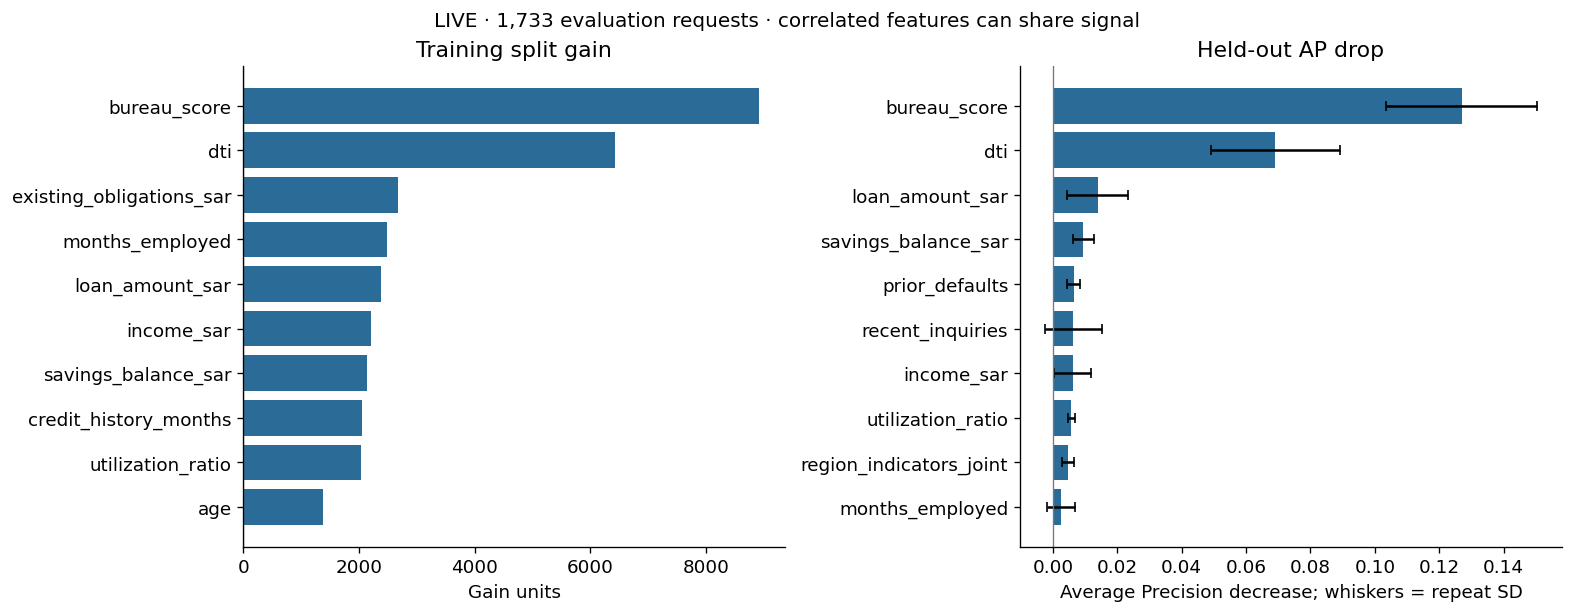

In [3]:
# Read held-out AP drop separately from training split gain.
permutation = permutation_report(model, parts["evaluation"], contract, config)
display(permutation[["feature_group", "mean_ap_drop", "repeat_sd", "training_gain"]].head(10).round(4))
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, value, title in [(axes[0], "training_gain", "Training split gain"), (axes[1], "mean_ap_drop", "Held-out AP drop")]:
    top = permutation.nlargest(10, value).sort_values(value)
    ax.barh(top.feature_group, top[value], color="#2b6b98",
            xerr=top.repeat_sd if value == "mean_ap_drop" else None, capsize=3)
    ax.axvline(0, color="#777", lw=.8); ax.set_title(title)
    ax.set_xlabel("Gain units" if value == "training_gain" else "Average Precision decrease; whiskers = repeat SD")
fig.suptitle(f"LIVE · {len(evaluation):,} evaluation requests · correlated features can share signal", fontsize=12)
fig.savefig(ARTIFACTS / "permutation_importance.png", bbox_inches="tight"); plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>4. Read the global SHAP explanation and its unit</h2>
<p>A fixed random evaluation sample is explained with TreeSHAP for the raw weighted model. The background is the training tree-path distribution; displayed feature values are the model inputs after fit-only imputation.</p>
<p><strong>raw margin = base value + Σ SHAP</strong>, followed by <strong>raw probability = sigmoid(raw margin)</strong>. SHAP values here are in <strong>log-odds</strong>, not probability points. Do not transform each contribution separately and add the transformed values. <code>sigmoid(base_value)</code> is not necessarily the mean predicted probability.</p>
<p>Read the beeswarm in four steps: mean absolute magnitude for rank, sign for score direction, colour for feature value and spread for heterogeneous effects. This explains model behaviour; it does not establish causality or fairness.</p>
<p>If the labelled educational example appears, it is for discussion only and cannot be submitted as the learner's own run.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>4. اقرأ تفسير SHAP العام ووحدته</h2>
<p>تُفسّر عينة عشوائية ثابتة من التقييم باستخدام TreeSHAP للنموذج الخام الموزون. تمثل الخلفية توزيع مسارات أشجار التدريب، وقيم الخصائص المعروضة هي مدخلات النموذج بعد التعويض المتعلم من fit فقط.</p>
<p><strong>raw margin = base value + مجموع SHAP</strong> ثم <strong>raw probability = sigmoid(raw margin)</strong>. قيم SHAP هنا بوحدة <strong>log-odds</strong> وليست نقاط احتمال. لا تحوّل كل مساهمة منفردة ثم تجمع القيم المحولة. كما أن <code>sigmoid(base_value)</code> ليس بالضرورة متوسط الاحتمالات المتوقعة.</p>
<p>اقرأ beeswarm بأربع خطوات: متوسط القيمة المطلقة للترتيب، والإشارة لاتجاه الدرجة، واللون لقيمة الخاصية، والانتشار لاختلاف الأثر. هذا تفسير لسلوك النموذج ولا يثبت السببية أو العدالة.</p>
<p>إذا ظهر المثال التعليمي الموسوم فهو للمناقشة فقط ولا يصلح للتسليم كتجربة المتدرب.</p>
</td>
</tr>
</table>

,feature,mean_absolute_shap_log_odds
4,bureau_score,0.9042
5,dti,0.5437
2,loan_amount_sar,0.3490
10,savings_balance_sar,0.2169
9,existing_obligations_sar,0.2022
8,prior_defaults,0.1830
6,months_employed,0.1584
1,income_sar,0.1549
7,recent_inquiries,0.1492
13,utilization_ratio,0.1287


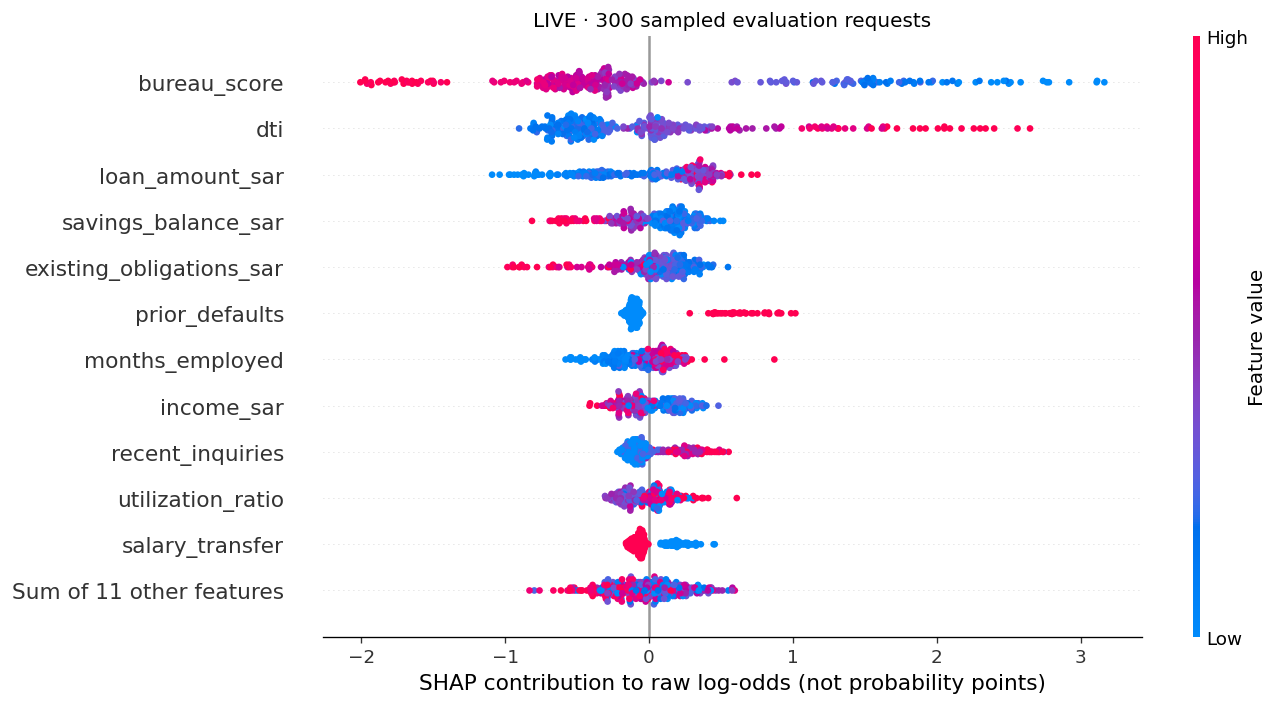

Maximum additivity error: 5.918876500032866e-15


In [4]:
# Interpret SHAP contributions in raw log-odds before applying any probability mapping.
try:
    if USE_SHAP_EXAMPLE:
        raise ShapBudgetExpired("Educational example requested.")
    shap_arrays, shap_metadata = explain_sample(model, parts["evaluation"], contract, config)
except ShapBudgetExpired:
    shap_arrays, shap_metadata = load_shap_example(ROOT / "data/day4_shap_example.npz",
        ROOT / "data/day4_shap_example.json", model, parts["evaluation"], contract, ASSESSMENT_MODE)

import shap
EXPLANATION_SOURCE = shap_metadata["source"]
if EXPLANATION_SOURCE != "LIVE":
    print("EDUCATIONAL_EXAMPLE — مثال موسوم للمناقشة، غير صالح للتسليم كتجربتك. أعد SHAP لاحقًا.")
explanation = shap.Explanation(values=shap_arrays["values"], base_values=shap_arrays["base_values"],
    data=shap_arrays["data"], feature_names=list(shap_arrays["feature_names"]))
shap_global = pd.DataFrame({"feature": shap_arrays["feature_names"],
    "mean_absolute_shap_log_odds": np.abs(shap_arrays["values"]).mean(axis=0)}).sort_values("mean_absolute_shap_log_odds", ascending=False)
display(shap_global.head(10).round(4))
plt.figure()
shap.plots.beeswarm(explanation, max_display=12, show=False, plot_size=(11, 6.5))
plt.xlabel("SHAP contribution to raw log-odds (not probability points)")
plt.title(f"{EXPLANATION_SOURCE} · {len(shap_arrays['application_ids'])} sampled evaluation requests", fontsize=12)
plt.savefig(ARTIFACTS / "shap_beeswarm.png", bbox_inches="tight"); plt.show()
print("Maximum additivity error:", shap_metadata["max_additivity_error"])

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>5. Explain one high-score synthetic request</h2>
<p>The lab selects the highest raw score inside the SHAP sample without using the observed outcome. The waterfall displays the largest contributions and groups the remainder; the complete contribution vector is preserved in the evidence file.</p>
<p>At most three reason statements are derived from actual positive contributions. Check whether the displayed input was imputed before interpreting it. A positive contribution does not mean the feature is always high, and changing the feature does not guarantee a changed outcome.</p>
<p>The <code>bureau_score ±1</code> perturbation is a narrow local stability check. It is not a guarantee for every request, feature or future period.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>5. فسّر طلبًا اصطناعيًا مرتفع الدرجة</h2>
<p>يختار اللاب أعلى درجة خام داخل عينة SHAP دون استخدام النتيجة المرصودة. تعرض waterfall أكبر الإسهامات وتجمع البقية، مع حفظ متجه الإسهامات الكامل في ملف الأدلة.</p>
<p>تُشتق ثلاث عبارات سبب كحد أقصى من الإسهامات الموجبة الفعلية. تحقّق أولًا هل القيمة المعروضة عُوّضت قبل تفسيرها. لا تعني المساهمة الموجبة أن الخاصية مرتفعة دائمًا، ولا يضمن تغيير الخاصية تغير النتيجة.</p>
<p>اختبار <code>bureau_score ±1</code> فحص محلي ضيق للاستقرار، وليس ضمانًا لكل طلب أو خاصية أو فترة مستقبلية.</p>
</td>
</tr>
</table>

TR-009585 | raw score=0.9031 | calibrated probability=0.4795


,feature,value_used,was_imputed,contribution_log_odds,reason_ar
0,bureau_score,497.0000,False,2.269325,استخدم النموذج درجة ائتمانية اصطناعية عند الطل...
1,dti,1.2806,False,1.198145,استخدم النموذج نسبة الالتزام مع القسط المقترح ...
2,loan_amount_sar,93437.2900,False,0.200725,استخدم النموذج مبلغ التمويل المطلوب بالقيمة 93...


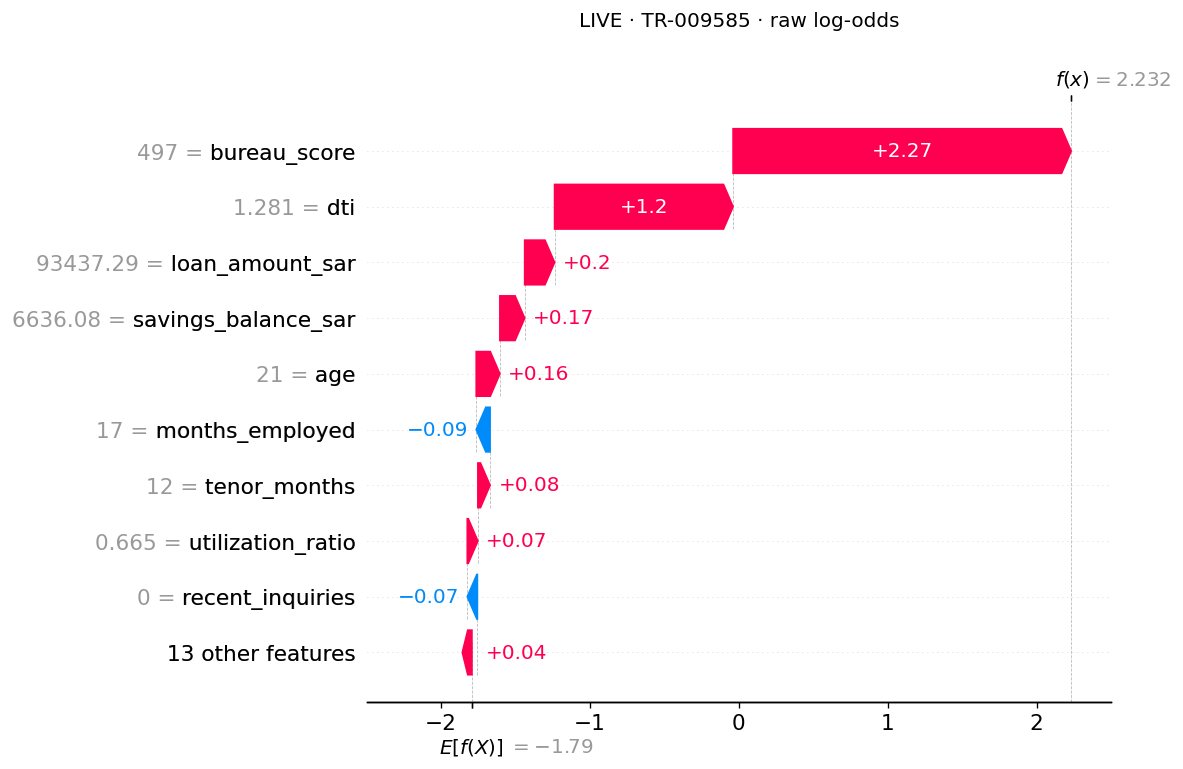

,perturbation,bureau_score_used,raw_probability,calibrated_probability,top_positive_features,shared_top_reasons,reference_reasons,source
0,bureau_score +0,497.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE
1,bureau_score -1,496.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE
2,bureau_score +1,498.0,0.903079,0.479518,bureau_score|dti|loan_amount_sar,3,3,LIVE


In [5]:
# Choose the example by model score alone so the observed outcome cannot influence the choice.
local_index = int(np.argmax(shap_arrays["raw_margin"]))
local_id = str(shap_arrays["application_ids"][local_index])
case = parts["evaluation"].set_index("application_id", drop=False).loc[[local_id]]
descriptions = {f["name"]: f["description_ar"] for f in contract["features"]}
reasons = reason_codes(shap_arrays["values"][local_index], shap_arrays["feature_names"],
    shap_arrays["data"][local_index], descriptions)
reasons["application_id"] = local_id
reasons["was_imputed"] = [bool(case.iloc[0][feature] != case.iloc[0][feature]) for feature in reasons.feature]
reasons["source"] = EXPLANATION_SOURCE
raw_local = float(expit(shap_arrays["raw_margin"][local_index]))
cal_local = float(map_probability(raw_local, mapping))
print(f"{local_id} | raw score={raw_local:.4f} | calibrated probability={cal_local:.4f}")
display(reasons[["feature", "value_used", "was_imputed", "contribution_log_odds", "reason_ar"]])
plt.figure()
shap.plots.waterfall(explanation[local_index], max_display=10, show=False)
plt.title(f"{EXPLANATION_SOURCE} · {local_id} · raw log-odds", fontsize=12, pad=45)
plt.savefig(ARTIFACTS / "shap_waterfall.png", bbox_inches="tight"); plt.show()
if EXPLANATION_SOURCE == "LIVE":
    local_checks = local_stability(model, case, contract, mapping)
    local_checks["source"] = "LIVE"
    display(local_checks)
else:
    local_checks = pd.DataFrame(columns=["perturbation", "bureau_score_used", "raw_probability", "calibrated_probability",
        "top_positive_features", "shared_top_reasons", "reference_reasons", "source"])
    print("Local perturbation check skipped in example mode; do not claim it ran.")

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>6. Test calibration on a separate period</h2>
<p>Sigmoid is learned on calibration rows only, without new class weights. The fitted model and calibrator are then frozen and measured on evaluation.</p>
<p>Compare ROC-AUC and Average Precision for ranking, and Brier score, log-loss and ECE for probability quality. A lower Brier score alone does not prove perfect calibration.</p>
<p>ECE uses ten equal-width bins: Σ(bin count ÷ all rows × |mean probability − observed rate|). Empty bins remain visible and every bin count is reported. ECE depends on bin boundaries and sample size; sparse bins are weak evidence.</p>
<p>A single monotone sigmoid mapping preserves the ordering of this model, but calibration is not guaranteed to improve. Isotonic calibration is optional and requires caution with the small number of calibration positives.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>6. اختبر المعايرة على فترة منفصلة</h2>
<p>يتعلم sigmoid من صفوف calibration فقط دون أوزان فئات جديدة. ثم يُثبّت النموذج والمعاير وتُقاس النتائج على evaluation.</p>
<p>قارن ROC-AUC وAverage Precision للترتيب، وBrier وlog-loss وECE لجودة الاحتمال. لا يثبت انخفاض Brier وحده المعايرة المثالية.</p>
<p>يستخدم ECE عشر حاويات متساوية العرض: مجموع (عدد الحاوية ÷ جميع الصفوف × |متوسط الاحتمال − التكرار المرصود|). تبقى الحاويات الفارغة ظاهرة ويُعرض عدد كل حاوية. يتأثر ECE بحدود الحاويات وحجم العينة؛ الحاويات القليلة دليل ضعيف.</p>
<p>يحافظ تحويل sigmoid المتزايد الواحد على ترتيب هذا النموذج، لكن التحسن غير مضمون. المعايرة isotonic توسع اختياري يحتاج حذرًا مع قلة الموجبات في عينة المعايرة.</p>
</td>
</tr>
</table>

,rows,positives,roc_auc,average_precision,brier,ece,log_loss
raw,1733,139,0.770804,0.258677,0.113027,0.146871,0.357993
sigmoid,1733,139,0.770804,0.258677,0.067112,0.022486,0.246749


Measured change (after - before): Brier -0.04592, ECE -0.12438


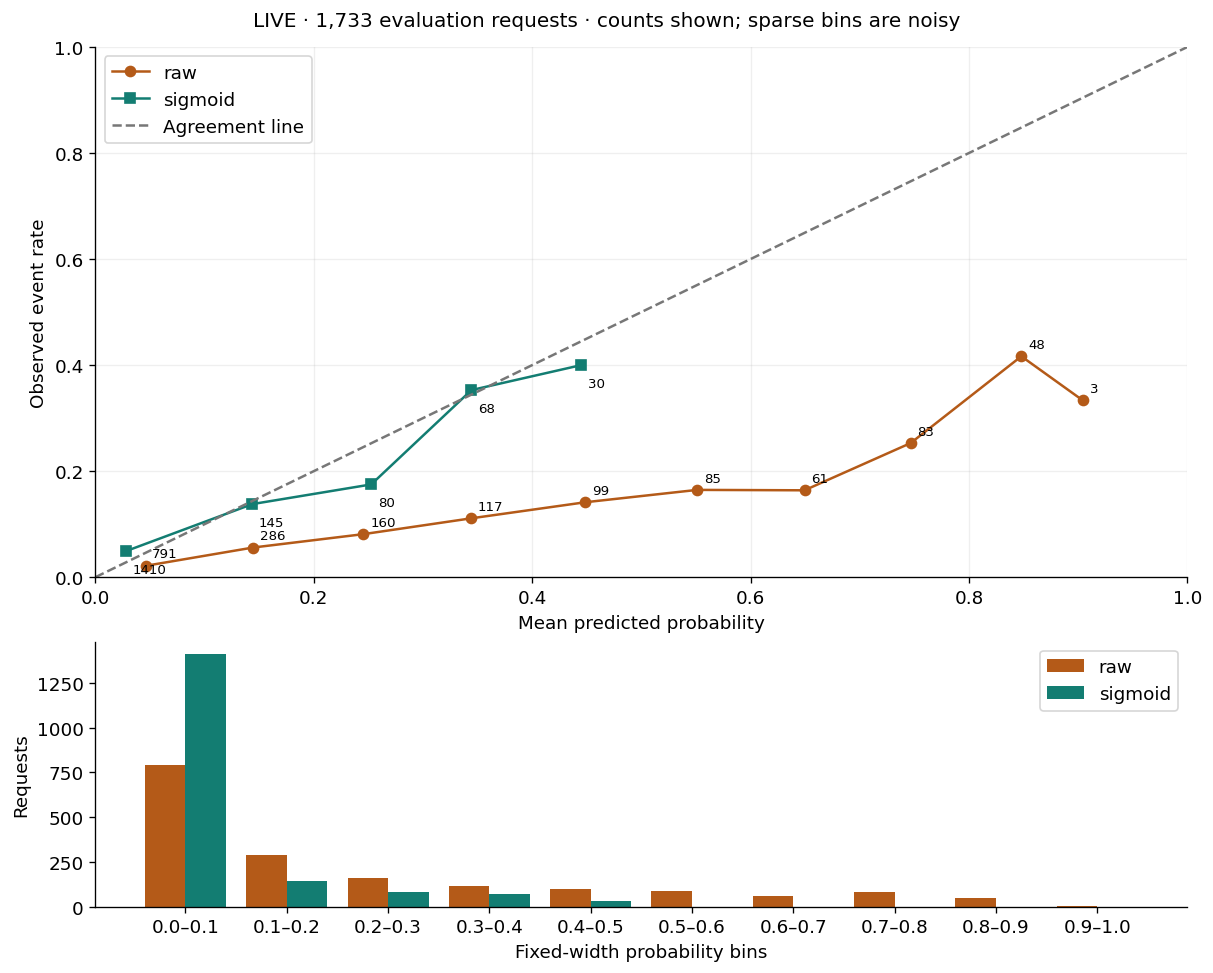

In [6]:
# Use the same evaluation requests and probability bins before and after calibration.
calibration_metrics, bin_tables = {}, []
for label, column in [("raw", "raw_probability"), ("sigmoid", "calibrated_probability")]:
    calibration_metrics[label] = probability_metrics(evaluation[TARGET], evaluation[column])
    table = reliability_table(evaluation[TARGET], evaluation[column]); table["variant"] = label
    bin_tables.append(table)
reliability = pd.concat(bin_tables, ignore_index=True)
display(pd.DataFrame(calibration_metrics).T[["rows", "positives", "roc_auc", "average_precision", "brier", "ece", "log_loss"]].round(5))
brier_delta = calibration_metrics["sigmoid"]["brier"] - calibration_metrics["raw"]["brier"]
ece_delta = calibration_metrics["sigmoid"]["ece"] - calibration_metrics["raw"]["ece"]
print(f"Measured change (after - before): Brier {brier_delta:+.5f}, ECE {ece_delta:+.5f}")
fig, axes = plt.subplots(2, 1, figsize=(10, 8), layout="constrained", gridspec_kw={"height_ratios": [2, 1]})
for label, color, marker in [("raw", "#b45a18", "o"), ("sigmoid", "#137d72", "s")]:
    bins = reliability[reliability.variant == label]; nonempty = bins[bins['count'] > 0]
    axes[0].plot(nonempty.mean_probability, nonempty.observed_rate, marker=marker, color=color, label=label)
    for row in nonempty.itertuples():
        axes[0].annotate(str(row.count), (row.mean_probability, row.observed_rate), xytext=(4, 5 if label == "raw" else -13), textcoords="offset points", fontsize=8)
    positions = bins['bin'] + (-.2 if label == "raw" else .2)
    axes[1].bar(positions, bins['count'], width=.4, color=color, label=label)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="#777", label="Agreement line")
axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Mean predicted probability", ylabel="Observed event rate")
axes[0].legend(); axes[0].grid(alpha=.2)
axes[1].set(xticks=np.arange(10), xticklabels=[f"{i/10:.1f}–{(i+1)/10:.1f}" for i in range(10)], ylabel="Requests", xlabel="Fixed-width probability bins")
axes[1].legend()
fig.suptitle(f"LIVE · {len(evaluation):,} evaluation requests · counts shown; sparse bins are noisy", fontsize=12)
fig.savefig(ARTIFACTS / "reliability_curve.png", bbox_inches="tight"); plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>7. Quantify what the stability interval does and does not cover</h2>
<p>The paired bootstrap samples <strong>customers</strong>, keeping each customer's requests together, and compares raw versus calibrated results on the same replicates. It reports 95% percentile intervals for AP and Brier change.</p>
<p>The model and calibrator remain fixed. The interval therefore excludes uncertainty from model training, calibration fitting and future temporal drift. It is not a confidence interval for one applicant's probability.</p>
<p>Quarter-level evaluation metrics describe temporal variation. They are not three independent folds or a confidence interval. Any change designed after viewing evaluation needs new evidence.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>7. حدّد ما تغطيه فترة الاستقرار وما لا تغطيه</h2>
<p>يسحب bootstrap المزدوج <strong>العملاء</strong> مع إبقاء طلبات العميل معًا، ويقارن النتائج الخام والمعايرة على السحبات نفسها. يعرض فترات مئينية 95% لـAP وتغير Brier.</p>
<p>يبقى النموذج والمعاير ثابتين؛ لذلك لا تشمل الفترة عدم يقين تدريب النموذج أو تعلم المعايرة أو الانجراف الزمني المستقبلي. كما أنها ليست فترة ثقة لاحتمال طلب واحد.</p>
<p>تصف مقاييس أرباع التقييم التغير الزمني، وليست طيات مستقلة أو فترة ثقة. أي تعديل يُصمم بعد رؤية التقييم يحتاج إلى دليل جديد.</p>
</td>
</tr>
</table>

,period,variant,rows,positives,average_precision,brier,ece
0,2024Q3,raw,836,78,0.27457,0.11528,0.13397
1,2024Q3,sigmoid,836,78,0.27457,0.07760,0.03229
2,2024Q4,raw,897,61,0.27050,0.11093,0.15890
3,2024Q4,sigmoid,897,61,0.27050,0.05734,0.02434


Paired customer-cluster 95% percentile intervals:


,lower,upper
raw_ap,0.197442,0.337854
calibrated_ap,0.197442,0.337854
brier_change,-0.054177,-0.037409


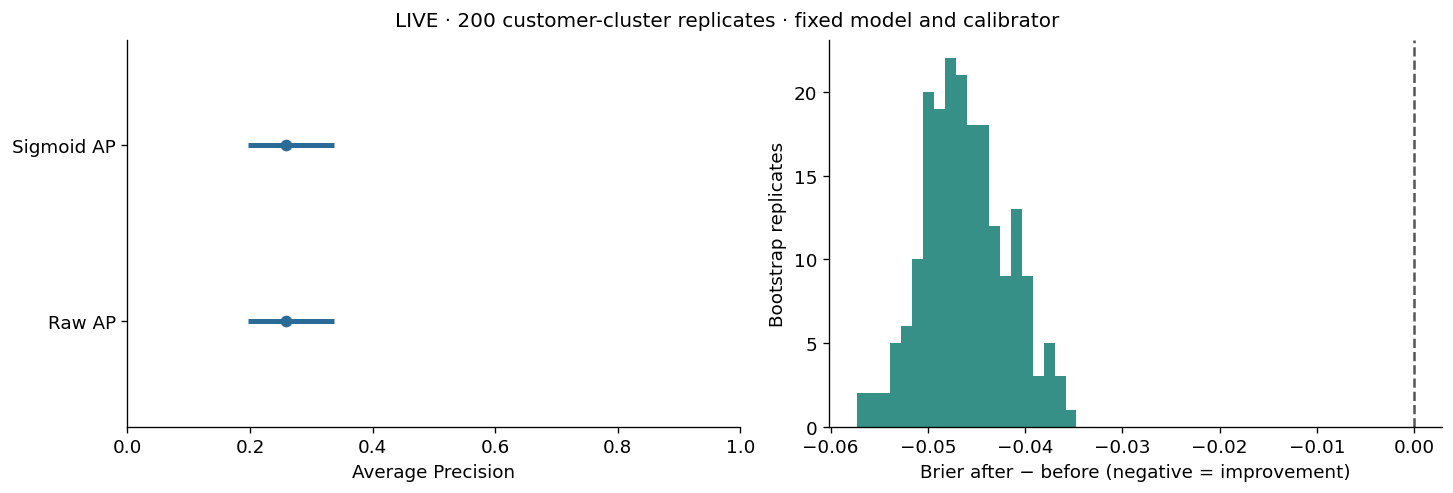

In [7]:
# Resample customers as a group while keeping the model and calibrator fixed.
bootstrap, stability_summary = cluster_bootstrap(evaluation, config)
period_rows = []
for period, group in evaluation.groupby(pd.to_datetime(evaluation.application_date).dt.to_period("Q").astype(str)):
    for variant, column in [("raw", "raw_probability"), ("sigmoid", "calibrated_probability")]:
        period_rows.append({"period": period, "variant": variant, **probability_metrics(group[TARGET], group[column])})
period_metrics = pd.DataFrame(period_rows)
display(period_metrics[["period", "variant", "rows", "positives", "average_precision", "brier", "ece"]].round(5))
stability_summary["period_ap_sample_sd"] = {v: float(g.average_precision.std(ddof=1)) for v, g in period_metrics.groupby("variant")}
print("Paired customer-cluster 95% percentile intervals:")
display(pd.DataFrame({key: stability_summary[key] for key in ("raw_ap", "calibrated_ap", "brier_change")}).T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
for i, key in enumerate(("raw_ap", "calibrated_ap")):
    interval = stability_summary[key]
    point = calibration_metrics["raw" if i == 0 else "sigmoid"]["average_precision"]
    if interval is not None:
        axes[0].hlines(i, interval["lower"], interval["upper"], color="#2b6b98", lw=3)
    axes[0].plot(point, i, "o", color="#2b6b98")
axes[0].set(yticks=[0, 1], yticklabels=["Raw AP", "Sigmoid AP"], xlabel="Average Precision", xlim=(0, 1), ylim=(-.6, 1.6))
axes[1].hist(bootstrap.brier_change, bins=20, color="#137d72", alpha=.85)
axes[1].axvline(0, color="#555", linestyle="--"); axes[1].set(xlabel="Brier after − before (negative = improvement)", ylabel="Bootstrap replicates")
fig.suptitle(f"LIVE · {stability_summary['valid']} customer-cluster replicates · fixed model and calibrator", fontsize=12)
fig.savefig(ARTIFACTS / "stability_summary.png", bbox_inches="tight"); plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>8. Test whether the review zone fits capacity</h2>
<p>The raw threshold was selected on the policy role only under the 10×FN+FP loss and a 12% capacity ceiling. It is transported through the monotone sigmoid mapping; it is not reselected on evaluation and is not copied from a different Day 3 model.</p>
<p>The ±0.02 probability zone is a diagnostic band for near-threshold cases, not individual uncertainty. When combining it with risk flags, count the union once. Capacity can fail in a later period even before adding the zone.</p>
<p><code>CAPACITY_REVIEW_REQUIRED</code> is a valid finding. Do not raise the ceiling, hide rows or retune the threshold after seeing evaluation. A revised policy must be developed and evaluated with new evidence.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>8. اختبر ملاءمة منطقة المراجعة للسعة</h2>
<p>اختيرت العتبة الخام على دور policy فقط ضمن خسارة 10×FN+FP وسقف سعة 12%. تُنقل عبر تحويل sigmoid المتزايد، ولا يُعاد اختيارها على evaluation ولا تُنسخ من نموذج مختلف في اليوم الثالث.</p>
<p>منطقة الاحتمال ±0.02 نطاق تشخيصي للحالات القريبة من العتبة وليست عدم يقين فرديًا. عند جمعها مع إشارات المخاطر احسب اتحاد المجموعتين مرة واحدة. قد تفشل السعة في فترة لاحقة حتى قبل إضافة المنطقة.</p>
<p>ظهور <code>CAPACITY_REVIEW_REQUIRED</code> نتيجة صحيحة. لا ترفع السقف ولا تُخفِ صفوفًا ولا تعِد ضبط العتبة بعد رؤية التقييم. يجب تطوير السياسة المعدلة وتقييمها بدليل جديد.</p>
</td>
</tr>
</table>

,threshold,flagged,fn,fp,loss_units,capacity,feasible,calibrated_threshold,selection_role
0,0.588195,68,34,47,387.0,70,True,0.17331,policy


,period,rows,capacity,risk_flags,near_threshold,candidate_review,risk_within_capacity,candidate_within_capacity,loss_units
0,2024Q3,836,100,97,23,109,True,False,536.0
1,2024Q4,897,107,109,21,122,False,False,444.0


CAPACITY_REVIEW_REQUIRED | Do not retune on evaluation.


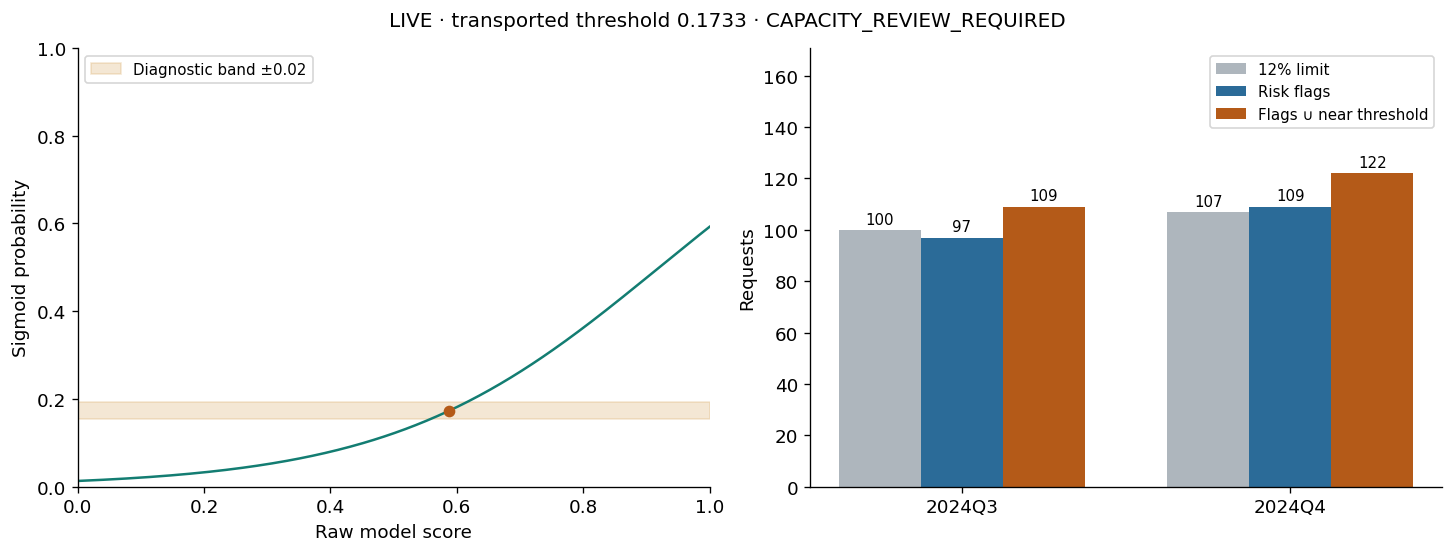

In [8]:
# Audit the union of the risk flags and near-cutoff rows against each period's capacity.
review_flags, capacity_audit, review_band = review_audit(evaluation, chosen_policy["threshold"],
    calibrated_threshold, config.review_half_width)
policy_status = "CAPACITY_REVIEW_REQUIRED" if not capacity_audit.candidate_within_capacity.all() else "WITHIN_OBSERVED_CAPACITY"
display(pd.DataFrame([{**chosen_policy, "calibrated_threshold": calibrated_threshold, "selection_role": "policy"}]))
display(capacity_audit)
print(policy_status, "| Do not retune on evaluation.")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
grid = np.linspace(0, 1, 300)
axes[0].plot(grid, map_probability(grid, mapping), color="#137d72")
axes[0].axhspan(review_band['lower'], review_band['upper'], color="#d7a354", alpha=.25, label="Diagnostic band ±0.02")
axes[0].plot(chosen_policy['threshold'], calibrated_threshold, 'o', color="#b45a18")
axes[0].set(xlim=(0, 1), ylim=(0, 1), xlabel="Raw model score", ylabel="Sigmoid probability")
axes[0].legend(loc="upper left", fontsize=9)
x = np.arange(len(capacity_audit))
for offset, column, label, color in [(-.25, 'capacity', '12% limit', '#aeb6bd'), (0, 'risk_flags', 'Risk flags', '#2b6b98'), (.25, 'candidate_review', 'Flags ∪ near threshold', '#b45a18')]:
    bars = axes[1].bar(x+offset, capacity_audit[column], width=.25, label=label, color=color)
    axes[1].bar_label(bars, padding=2, fontsize=9)
axes[1].set(xticks=x, xticklabels=capacity_audit.period, ylabel="Requests", ylim=(0, capacity_audit.candidate_review.max()*1.4))
axes[1].legend(fontsize=9)
fig.suptitle(f"LIVE · transported threshold {calibrated_threshold:.4f} · {policy_status}", fontsize=12)
fig.savefig(ARTIFACTS / "review_zone.png", bbox_inches="tight"); plt.show()

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>9. Write the interpretation supported by your evidence</h2>
<p>Complete all six fields in <code>responses</code> and cite your measured values and denominators:</p>
<ol><li>global versus local explanation;</li><li>SHAP output unit and background;</li><li>limits of reason statements and correlated features;</li><li>calibration evidence on the separate period;</li><li>what the stability interval includes and excludes;</li><li>the review zone's effect on period capacity.</li></ol>

</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>9. اكتب تفسيرًا تدعمه أدلتك</h2>
<p>أكمل الحقول الستة داخل <code>responses</code> واستشهد بالقيم المقاسة ومقاماتها:</p>
<ol><li>الفرق بين التفسير العام والمحلي؛</li><li>وحدة SHAP وخلفيته؛</li><li>حدود عبارات السبب والخصائص المترابطة؛</li><li>دليل المعايرة على الفترة المنفصلة؛</li><li>ما تشمله فترة الاستقرار وما تستبعده؛</li><li>أثر منطقة المراجعة في سعة كل فترة.</li></ol>
<p>يحوّل اكتمال النصوص بوابة المتدرب إلى جاهز للمراجعة، لكنه لا يتحقق من صحة الإجابات ولا يمنح درجة آلية.</p>
</td>
</tr>
</table>

In [9]:
responses = {'global_local': 'Global means aggregate contributions across 300 evaluation applications. bureau_score '
                 'led both mean absolute SHAP (0.9042) and drop in AP after shuffling (0.1270). In the '
                 'high-scoring example, the local waterfall attributes that single raw score to the '
                 'individual features and baseline.',
 'output_units': 'Tree SHAP uses training-path counts as background and reports contributions to the '
                 'raw, uncalibrated log-odds of the weighted LightGBM. These contributions add to the '
                 'raw margin with the base value.',
 'reason_limits': 'SHAP and permutation report this fitted model’s reliance on a feature. Correlated '
                  'predictors can share the signal, so the ranking cannot estimate the effect of '
                  'changing someone’s score.',
 'calibration_evidence': 'On the separate 1,733-row evaluation period, Brier fell from 0.11303 to '
                         '0.06711 and ECE from 0.14687 to 0.02249. AP remained 0.25868 under the '
                         'increasing sigmoid.',
 'stability': 'The 200 paired customer-level resamples gave a 95% interval from -0.05418 to -0.03741 '
              'for the Brier change. The interval conditions on the fitted model and calibrator and '
              'omits retraining and future population drift.',
 'review_capacity': 'Combining flags with cases in the diagnostic band raised the queue from 97 to 109 '
                    'against 100 slots in Q3, and from 109 to 122 against 107 slots in Q4. Both '
                    'quarters exceeded capacity; Q4 exceeded it on risk flags alone.'}
checkpoint = reflection_check(responses, EXPLANATION_SOURCE)
print(checkpoint["status"], "| Fields to complete:", checkpoint["missing"])

READY_FOR_REVIEW | Fields to complete: []


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>10. Export the report and evidence bundle</h2>
<p>Re-run the export cell after completing <code>responses</code>. Download <code>artifacts/day4_artifacts.zip</code> and keep its <code>artifacts/</code> and <code>reports/</code> structure. Save the executed notebook as <code>notebooks/04_explain_calibrate.ipynb</code>.</p>
<p>The bundle contains 12 CSV tables, six analysis JSON files plus the environment record, a compressed NPZ of complete SHAP values, the LightGBM model text, six PNG figures and <code>reports/INTERPRETABILITY_REPORT.md</code>.</p>
<p>Read probability CSV files with <code>float_precision="round_trip"</code> when exact round trips matter. A technically successful run can still require learner work or capacity review. Educational-example mode is not submittable and is blocked in assessment mode.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>10. صدّر التقرير وحزمة الأدلة</h2>
<p>أعد تشغيل خلية التصدير بعد إكمال <code>responses</code>. نزّل <code>artifacts/day4_artifacts.zip</code> واحتفظ بهيكل <code>artifacts/</code> و<code>reports/</code>. احفظ الدفتر المنفذ باسم <code>notebooks/04_explain_calibrate.ipynb</code>.</p>
<p>تضم الحزمة 12 جدول CSV وستة ملفات JSON تحليلية إضافة إلى سجل البيئة، وملف NPZ مضغوط لقيم SHAP الكاملة، ونص نموذج LightGBM، وستة رسوم PNG، وملف <code>reports/INTERPRETABILITY_REPORT.md</code>.</p>
<p>استخدم <code>float_precision="round_trip"</code> عند إعادة قراءة ملفات الاحتمالات إذا كانت الاستعادة الدقيقة مهمة. قد ينجح التشغيل تقنيًا مع بقاء عمل على المتدرب أو مراجعة للسعة. وضع المثال التعليمي غير صالح للتسليم ويُحظر في وضع التقييم.</p>
</td>
</tr>
</table>

In [10]:
# Keep the capacity status beside the technical status so the evidence records both results.
def json_safe(value):
    if isinstance(value, dict): return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple, np.ndarray)): return [json_safe(v) for v in value]
    if isinstance(value, (np.integer,)): return int(value)
    if isinstance(value, (np.bool_,)): return bool(value)
    if isinstance(value, (float, np.floating)): return float(value) if np.isfinite(value) else None
    return value

technical_status = "TECHNICAL_READY" if EXPLANATION_SOURCE == "LIVE" else "EXAMPLE_ONLY_NOT_SUBMITTABLE"
calibration_payload = {"source": "LIVE", "evaluation_role": "evaluation", "metrics": calibration_metrics,
    "mapping": mapping, "policy_selection": chosen_policy, "calibrated_threshold": calibrated_threshold,
    "review_band": review_band, "capacity_status": policy_status, "brier_change": brier_delta, "ece_change": ece_delta,
    "prior_course_exposure": True, "not_a_final_untouched_test": True}
run = {"technical_status": technical_status, "learner_status": checkpoint["status"],
    "explanation_source": EXPLANATION_SOURCE, "model_calibration_source": "LIVE", "config": asdict(config),
    "assessment_mode": ASSESSMENT_MODE, "lab_revision": LAB_REVISION, "support_sha256": SUPPORT_HASHES,
    "previous_support": PREVIOUS_SUPPORT, "data_revision": COURSE_REVISION, "python": platform.python_version(),
    "elapsed_seconds": round(time.perf_counter()-RUN_STARTED, 2), "capacity_status": policy_status,
    "challenge_used_for_modeling": False, "no_automatic_grade": True}
csv_outputs = {"day4_roles.csv": assignments, "day4_predictions.csv": predictions,
    "permutation_importance.csv": permutation, "day4_shap_global.csv": shap_global.assign(source=EXPLANATION_SOURCE),
    "day4_reason_codes.csv": reasons, "day4_local_stability.csv": local_checks,
    "day4_reliability_bins.csv": reliability, "day4_period_metrics.csv": period_metrics,
    "day4_bootstrap.csv": bootstrap, "day4_policy_sweep.csv": policy_sweep,
    "day4_review_flags.csv": review_flags, "day4_capacity.csv": capacity_audit}
for filename, table in csv_outputs.items(): table.to_csv(ARTIFACTS / filename, index=False)
np.savez_compressed(ARTIFACTS / "shap_values_sample.npz", **shap_arrays)
model.named_steps["model"].booster_.save_model(str(ARTIFACTS / "day4_model.txt"))
json_outputs = {"calibration_metrics.json": calibration_payload, "day4_shap_metadata.json": shap_metadata,
    "day4_stability_summary.json": stability_summary, "day4_provenance.json": provenance,
    "day4_reflection.json": {"responses": responses, "checkpoint": checkpoint}, "day4_run.json": run}
for filename, payload in json_outputs.items():
    (ARTIFACTS / filename).write_text(json.dumps(json_safe(payload), ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
answer = lambda key: responses[key].strip() or "[اكتب تفسيرك من نتائجك هنا]"
status_text = "مثال تعليمي غير صالح للتسليم كتجربة شخصية" if EXPLANATION_SOURCE != "LIVE" else ("مسودة — أكمل تفسيرك" if checkpoint['missing'] else "جاهز للمراجعة؛ لا يعني اعتمادًا أو درجة")
reason_text = "\n".join(f"- {r.reason_ar} (SHAP={r.contribution_log_odds:+.4f} log-odds؛ قيمة معوضة: {r.was_imputed})" for r in reasons.itertuples())
capacity_text = "\n".join(f"- {r.period}: السقف {r.capacity}، الإشارات {r.risk_flags}، اتحاد المراجعة {r.candidate_review}." for r in capacity_audit.itertuples())
report = f"""# تقريرك: التفسير والمعايرة — Tamweel Lite

**الحالة:** {status_text}

**مصدر التفسير:** {EXPLANATION_SOURCE}. **النموذج والمعايرة:** LIVE. **السعة:** {policy_status}.

## النموذج والأدوار
LightGBM موزون، {config.trees} شجرة. الهدف حدث تعثر اصطناعي خلال90 يومًا بعد الطلب. الأدوار منفصلة زمنيًا وبالعملاء: تدريب {len(parts['fit'])}، معايرة {len(parts['calibration'])} ({int(parts['calibration'][TARGET].sum())} موجب)، سياسة {len(parts['policy'])}، تقييم {len(evaluation)}. الفجوات والتداخلات مستبعدة. سبق استخدام بيانات التقييم في الدورة، فهي ليست اختبارًا نهائيًا لم يمسّ.

## التفسير العام والمحلي
Permutation يقيس انخفاضAP على التقييم؛ إشارات المنطقة تُبدّل معًا. SHAP يفسر النموذج الخام بوحدةlog-odds وخلفية مسارات أشجار التدريب. base+sum(SHAP)=raw margin، ثمsigmoid للمجموع فقط. القيم ليست نقاط احتمال ولا تفسيرًا مباشرًا للنموذج المعاير.

{answer('global_local')}

{answer('output_units')}

الطلب الاصطناعي {local_id}: الدرجة الخام {raw_local:.5f} والاحتمال المعاير {cal_local:.5f}. اختير أعلى درجة داخل عينةSHAP دون استخدام النتيجة الفعلية.
{reason_text}

{answer('reason_limits')}

## دليل المعايرة
على {len(evaluation)} صفًا و{int(evaluation[TARGET].sum())} موجب: Brier {calibration_metrics['raw']['brier']:.6f} → {calibration_metrics['sigmoid']['brier']:.6f}؛ ECE {calibration_metrics['raw']['ece']:.6f} → {calibration_metrics['sigmoid']['ece']:.6f}. عشر حاويات متساوية العرض مع أعدادها فيday4_reliability_bins.csv. AP {calibration_metrics['raw']['average_precision']:.6f} → {calibration_metrics['sigmoid']['average_precision']:.6f}؛ ROC-AUC {calibration_metrics['raw']['roc_auc']:.6f} → {calibration_metrics['sigmoid']['roc_auc']:.6f}. هذه نتائج هذه العينة وليست ضمانًا لتحسن مستقبلي.

{answer('calibration_evidence')}

## الاستقرار
{stability_summary['valid']} تكرارbootstrap صالح بسحب العملاء؛ فترات مئينية95% مع تثبيت النموذج والمعاير. لا تشمل تعلم النموذج أو المعايرة أو الانجراف المستقبلي، ولا تصف احتمال فرد. انحرافAP بين ربعي التقييم وصفي فقط. اختبارbureau_score±1 {'نُفذ؛ راجع day4_local_stability.csv' if EXPLANATION_SOURCE == 'LIVE' else 'لم ينفذ في وضع المثال'}.

{answer('stability')}

## العتبة ومنطقة المراجعة
العتبة الخام {chosen_policy['threshold']!r} اختيرت علىpolicy بخسارة10×FN+FP وسقف12% ثم نُقلت إلى {calibrated_threshold!r}. لم تعدل باستخدام التقييم. المنطقة[{review_band['lower']:.5f}, {review_band['upper']:.5f}] تشخيصية بعرض±0.02 وليست فترة ثقة. الاتحاد يحسب الطلب مرة واحدة.
{capacity_text}

{answer('review_capacity')}

عند تجاوز السعة، وثّق الحاجة إلى تصميم سياسة جديدة على بيانات تطوير وتقييمها بدليل جديد. لا ترفع السقف ولا تقص الحالات بعد رؤية النتيجة. التفسير ليس سببية أو شهادة عدالة، والخسارة وحدات تعليمية لا رسوم أو خصم درجات. لا يستخدم هذا التمرين لتمويل حقيقي.
"""
(REPORTS / "INTERPRETABILITY_REPORT.md").write_text(report, encoding="utf-8")
figures = ["permutation_importance.png", "shap_beeswarm.png", "shap_waterfall.png", "reliability_curve.png", "stability_summary.png", "review_zone.png"]
artifact_files = list(csv_outputs) + list(json_outputs) + figures + ["environment.json", "shap_values_sample.npz", "day4_model.txt"]
with zipfile.ZipFile(ARTIFACTS / "day4_artifacts.zip", "w", zipfile.ZIP_DEFLATED) as bundle:
    for filename in artifact_files: bundle.write(ARTIFACTS / filename, "artifacts/" + filename)
    bundle.write(REPORTS / "INTERPRETABILITY_REPORT.md", "reports/INTERPRETABILITY_REPORT.md")
print(f"{technical_status} | {checkpoint['status']} | {EXPLANATION_SOURCE} | CPU")
print(f"Saved {len(artifact_files)+1} files in day4_artifacts.zip | {policy_status}")

TECHNICAL_READY | READY_FOR_REVIEW | LIVE | CPU
Saved 28 files in day4_artifacts.zip | CAPACITY_REVIEW_REQUIRED


<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Before moving to Day 5</h2>
<p>Open all six figures and verify units, denominators, labels and explanation source. Be able to explain why one monotone mapping can preserve rank, why SHAP contributions do not establish causality and why near-threshold review needs a separate capacity calculation.</p>
<p>If an educational SHAP example was used, rerun live SHAP on CPU before submission; never present the example as your own experiment.</p>
<p><a href="https://github.com/almiyead-rgb/sda-dsc-211-student-template/blob/main/DAY4_GUIDE.md">Day 4 guide</a> · <a href="https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html">TreeExplainer output units</a> · <a href="https://scikit-learn.org/1.6/modules/generated/sklearn.calibration.CalibratedClassifierCV.html">Frozen-model calibration</a></p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>قبل الانتقال إلى اليوم الخامس</h2>
<p>افتح الرسوم الستة وتحقق من الوحدات والمقامات والعناوين ومصدر التفسير. يجب أن تستطيع شرح سبب محافظة تحويل متزايد واحد على الترتيب، ولماذا لا تثبت مساهمات SHAP السببية، ولماذا تحتاج مراجعة الحالات القريبة إلى حساب مستقل للسعة.</p>
<p>إذا استُخدم مثال SHAP التعليمي فأعد تشغيل SHAP المباشر على CPU قبل التسليم، ولا تعرض المثال بوصفه تجربتك.</p>
<p><a href="https://github.com/almiyead-rgb/sda-dsc-211-student-template/blob/main/DAY4_GUIDE.md">دليل اليوم الرابع</a> · <a href="https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html">وحدات TreeExplainer</a> · <a href="https://scikit-learn.org/1.6/modules/generated/sklearn.calibration.CalibratedClassifierCV.html">معايرة نموذج مجمد</a></p>
</td>
</tr>
</table>

<table style="width:100%; border-collapse:collapse;">
<tr>
<td width="50%" valign="top" dir="ltr" style="padding:14px; border:1px solid #d0d7de;">
<h2>Daily question · Interpretation and calibration</h2>
<p><strong>Which feature was most important in your explanation, and why does that not prove causality?</strong><br><br>Write a short answer under <code>Day 4</code> in the <code>Daily answers | الإجابات اليومية</code> section of your repository README. Then download this executed notebook and the required generated files and upload them on the same day.</p>
</td>
<td width="50%" valign="top" dir="rtl" style="padding:14px; border:1px solid #d0d7de;">
<h2>سؤال اليوم · التفسير والمعايرة</h2>
<p><strong>ما أهم خاصية في تفسيرك، ولماذا لا يثبت ذلك السببية؟</strong><br><br>اكتب إجابة مختصرة تحت <code>Day 4 | اليوم 4</code> في قسم <code>Daily answers | الإجابات اليومية</code> داخل README في مستودعك، ثم نزّل هذا الدفتر بعد التنفيذ وملفات النتائج المطلوبة وارفعها في اليوم نفسه.</p>
</td>
</tr>
</table>

## Daily answer | إجابة اليوم

`bureau_score`, the synthetic credit score available at application time, was the most important feature in my explanation. It had the largest mean absolute SHAP value across 300 evaluation applications (0.9042 raw log-odds). Shuffling it also caused the largest average drop in Average Precision (0.1270). Both results show how much the fitted model relied on the score. They do not show that changing the score would change someone's default risk. Credit score can reflect other correlated factors, and this lab did not test an intervention.